# Schelling segregation model

Two groups of agents live on a 30 × 30 grid with 10% empty cells. An agent is unhappy if fewer than a fraction h of its occupied neighbours are its own type. Unhappy agents move to a random empty cell. Slides 11–14.

*Made for this site, following the rules on the slides (`1 Lecture/Agent Based Modelling with Mesa - Slides.html`). It uses Mesa 3 (`mesa.discrete_space`), tested with Mesa 3.5.1 in the browser. The interactive Solara versions on py.cafe, linked from the slides, need the internet and run outside this site.*

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install mesa networkx

In [2]:
import mesa
from mesa.discrete_space import OrthogonalMooreGrid, CellAgent
import numpy as np
import matplotlib.pyplot as plt

**The model.** Similarity s_i = same-type neighbours / occupied neighbours (s_i = 1 with no neighbours).

In [3]:
class Resident(CellAgent):
    def __init__(self, model, cell, group):
        super().__init__(model)
        self.cell = cell
        self.group = group

    def similarity(self):
        others = [a for a in self.cell.neighborhood.agents]
        return 1.0 if not others else sum(a.group == self.group for a in others) / len(others)

    def step(self):
        if self.similarity() < self.model.h:
            self.cell = self.model.grid.select_random_empty_cell()
            self.model.moves += 1


class Schelling(mesa.Model):
    def __init__(self, size=30, density=0.9, minority=0.5, h=0.3, seed=1):
        super().__init__(rng=seed)
        self.h = h
        self.grid = OrthogonalMooreGrid((size, size), torus=True, capacity=1, random=self.random)
        for cell in self.grid.all_cells:
            if self.random.random() < density:
                Resident(self, cell, 1 if self.random.random() < minority else 0)
        self.moves = 0

    def step(self):
        self.moves = 0
        self.agents.shuffle_do("step")

    def mean_similarity(self):
        return np.mean([a.similarity() for a in self.agents])

    def picture(self):
        w, h = self.grid.dimensions
        img = np.full((h, w), np.nan)
        for a in self.agents:
            x, y = a.cell.coordinate
            img[y, x] = a.group
        return img

**Run it** with a mild preference, h = 0.3: each agent is content if only 30% of its neighbours are like it. Predict first: how segregated does the town become?

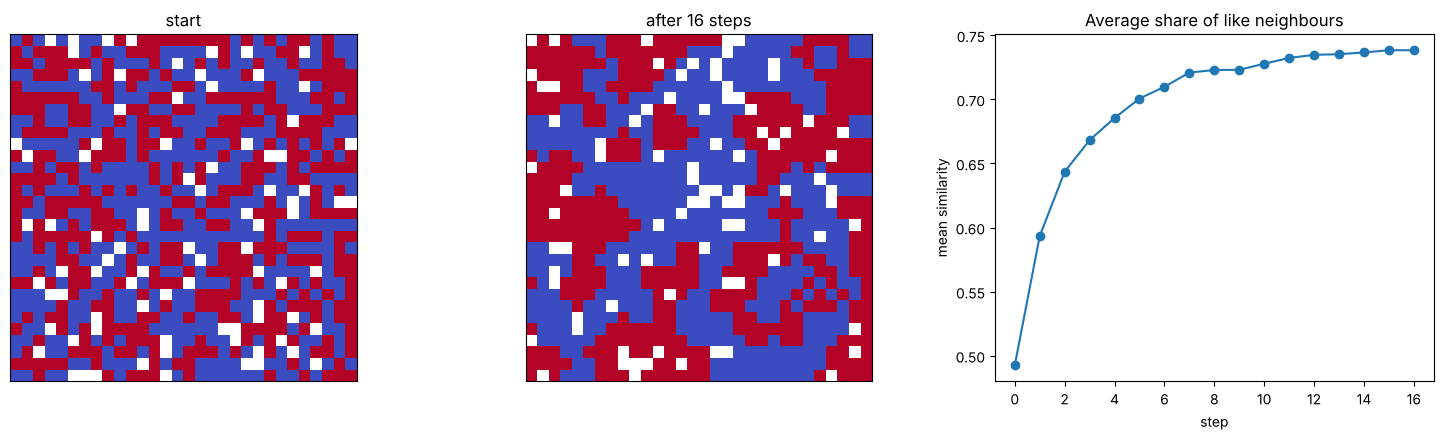

Mean similarity: 0.49 at the start, 0.74 at the end, with h = 0.3


In [4]:
def run(h, steps=30, seed=1):
    m = Schelling(h=h, seed=seed)
    start = m.picture(); sims = [m.mean_similarity()]
    for _ in range(steps):
        m.step(); sims.append(m.mean_similarity())
        if m.moves == 0:
            break
    return m, start, sims

model, start, sims = run(h=0.3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(start, cmap="coolwarm", interpolation="nearest"); axes[0].set(title="start", xticks=[], yticks=[])
axes[1].imshow(model.picture(), cmap="coolwarm", interpolation="nearest"); axes[1].set(title=f"after {len(sims) - 1} steps", xticks=[], yticks=[])
axes[2].plot(sims, marker="o"); axes[2].set(xlabel="step", ylabel="mean similarity", title="Average share of like neighbours")
plt.tight_layout(); plt.show()
print(f"Mean similarity: {sims[0]:.2f} at the start, {sims[-1]:.2f} at the end, with h = 0.3")

**Experiment.** How does the final similarity change with h?

In [5]:
for h in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6):
    _, _, sims = run(h, steps=50)
    print(f"h = {h:.1f}: final mean similarity {sims[-1]:.2f}")

h = 0.1: final mean similarity 0.50
h = 0.2: final mean similarity 0.56
h = 0.3: final mean similarity 0.74


h = 0.4: final mean similarity 0.83


h = 0.5: final mean similarity 0.88


h = 0.6: final mean similarity 0.97
